# EPR spin systems with `epreasy`

`epreasy` is a separate package in this repository (`import epreasy`) that
ports [EasySpin](https://easyspin.org), the MATLAB toolbox for EPR spectral
simulation by Stefan Stoll and co-workers, to Python. It keeps EasySpin's
interface: spin systems are dicts with EasySpin's field names, fields are in
mT, energies in MHz, Euler angles are EasySpin's passive rotations, and spin
numbers are 1-based. This guide covers the foundation (spin systems, spin
operators, the spin Hamiltonian and its field split, energy levels,
rotations, units and nuclear data), the resonance-field layer, and the first
two simulators: `pepper` for powders and crystals and `garlic` for isotropic
solutions. The companion notebook is [`notebooks/epreasy.ipynb`](epreasy.ipynb)
([interactive figures on nbviewer](https://nbviewer.org/github/ajerschow/spynach/blob/main/docs/notebooks/epreasy.ipynb)).

`epreasy` depends on `spynach` and changes nothing in it; the Spinach port
stays the core of this repository. For what carries over from EasySpin and
what differs, see [Coming from EasySpin](coming-from-easyspin.ipynb).

*Generated from [`docs/epreasy.md`](../epreasy.md) by `docs/build_notebooks.py`; edit the Markdown guide, not this notebook.*

Run the cells in order: later cells use names defined by earlier ones. The saved outputs come from running the notebook top to bottom; plotting cells need Plotly (`pip install -e ".[docs]"`).

## Contents

1. [A spin system](#A-spin-system)
2. [Spin operators](#Spin-operators)
3. [The spin Hamiltonian and its field split](#The-spin-Hamiltonian-and-its-field-split)
4. [Energy levels](#Energy-levels)
5. [Rotations, units, nuclear data](#Rotations,-units,-nuclear-data)
6. [Resonance fields](#Resonance-fields)
7. [Line shapes and spherical grids](#Line-shapes-and-spherical-grids)
8. [Powder and crystal spectra: `pepper`](#Powder-and-crystal-spectra:-pepper)
9. [Solution spectra: `garlic`](#Solution-spectra:-garlic)
10. [What is checked, and what is pending](#What-is-checked,-and-what-is-pending)

## A spin system

A spin system is a dict with EasySpin's fields: `S` (electron spins, default
1/2), `g` with `gFrame`, `Nucs` (a comma-separated isotope string), `A` with
`AFrame` (MHz), `D` with `DFrame` (MHz), `Q` with `QFrame`, electron-electron
couplings as `ee` or as `J`, `dip`, `dvec`, nuclear-nuclear couplings `nn`,
Stevens-operator terms `B2`..`B12`, line widths and strains. Numbers follow
MATLAB's shapes: a flat list is one row, so the three values below are the
principal values of one g tensor and `A=[16, 86]` would be an axial tensor.
`validatespinsys` checks the dict and returns a copy in EasySpin's processed
layout, with every tensor as a 2-D array of one row per spin and the derived
fields `I`, `gn`, `Spins` and `nStates` added.

In [1]:
import numpy as np

import epreasy as es

print(es.__version__)

spin_system = {
    "g": [2.0088, 2.0061, 2.0027],
    "gFrame": np.deg2rad([10, 20, 30]),
    "Nucs": "14N",
    "A": [16, 16, 86],  # MHz
    "AFrame": [0.3, 0.7, 1.1],  # radians, Euler angles of the A frame in the molecular frame
    "Q": [-0.5, 0.2],  # e^2 q Q / h in MHz and eta
    "lwpp": 0.3,  # mT, peak-to-peak Gaussian line width
}
full = es.validatespinsys(spin_system)
print(full["Spins"], full["nStates"])
print("Q principal values (MHz):", full["Q"].round(4), "   lw (FWHM, mT):", full["lw"].round(4))

0.1.0
[0.5 1. ] 6
Q principal values (MHz): [[ 0.1   0.15 -0.25]]    lw (FWHM, mT): [0.3532 0.    ]


Shorthands expand as in EasySpin: a scalar `g` is isotropic, two values are
axial, `D=[D, E]` gives the principal values `(-D/3+E, -D/3-E, 2D/3)`,
`Q=[eeqQ/h, eta]` the quadrupole principal values for the nucleus's spin,
and `lwpp` becomes `lw` (full width at half maximum). Nuclei of spin zero are
removed, and errors are EasySpin's: a missing `A`, a wrong size, `ee`
together with `J`, a mis-capitalised field name.

In [2]:
mn = {"S": 5 / 2, "D": [1000, 100], "DFrame": [0.2, 0.5, 0.9], "B4": [1, 2, -3, 0.5, 10, -0.5, 3, -2, 1], "Nucs": "55Mn", "A": 250}
print("D principal values:", es.validatespinsys(mn)["D"].round(2))
print("states:", es.hsdim(mn), " spins:", es.spinvec(mn))
try:
    es.validatespinsys({"nucs": "1H", "A": 1})
except ValueError as error:
    print("error:", error)

D principal values: [[-233.33 -433.33  666.67]]
states: 36  spins: [2.5 2.5]
error: Fix capitalization: Sys.nucs should be Sys.Nucs


## Spin operators

`sop` builds spin operator matrices in EasySpin's basis `|mS, mI, ...>` (first
spin slowest, `m` descending), from a vector of spin quantum numbers or a
spin system, with EasySpin's three syntaxes: one component letter per spin
(`'xye'`), component and spin number (`'x1y2'` or `'x1,y2'`), and
transition-selective operators (`'x(1|3)'` connects levels 1 and 3). The
letters are `e`, `x`, `y`, `z`, `+`, `-`, and `a`, `b` for the two states of a
spin-1/2. Several specifications give a tuple; `sparse=True` gives
`scipy.sparse` matrices.

In [3]:
Sx, Sy, Sz = es.sop(1, "x", "y", "z")
print("[Sx, Sy] = i Sz:", np.allclose(Sx @ Sy - Sy @ Sx, 1j * Sz))
print("diagonal of Sz for S = 1:", np.diag(Sz).real)
SxIz = es.sop([1 / 2, 1], "xz")
print("SxIz is 6 x 6, the same as", np.allclose(SxIz, es.sop([1 / 2, 1], "x1,z2")), "for 'x1,z2'")
print("Sx on the 1-3 transition of S = 1:")
print(es.sop(1, "x(1|3)").real)

[Sx, Sy] = i Sz: True
diagonal of Sz for S = 1: [ 1.  0. -1.]
SxIz is 6 x 6, the same as True for 'x1,z2'
Sx on the 1-3 transition of S = 1:
[[0.  0.  0.5]
 [0.  0.  0. ]
 [0.5 0.  0. ]]


`stev` gives the extended Stevens operators `O_k^q`; `q >= 0` is the cosine
operator, `q < 0` the sine one, and `k` runs up to `2S` (at most 12). Their
coefficients are the `B2`..`B12` rows of a spin system, ordered from `q = +k`
to `-k`.

In [4]:
O20 = es.stev(5 / 2, 2, 0)
S = 5 / 2
print("O_2^0 = 3 Sz^2 - S(S+1):", np.allclose(O20, 3 * es.sop(S, "z") @ es.sop(S, "z") - S * (S + 1) * np.eye(6)))
print("O_4^2 of the first spin in a two-spin system:", es.stev([5 / 2, 1 / 2], 4, 2, ispin=1).shape)

O_2^0 = 3 Sz^2 - S(S+1): True
O_4^2 of the first spin in a two-spin system: (12, 12)


## The spin Hamiltonian and its field split

The Hamiltonian is assembled as in EasySpin: the field-independent part `H0`
from the zero-field splitting (`ham_zf`, with the Stevens terms), the
electron-electron (`ham_ee`), hyperfine (`ham_hf`), nuclear quadrupole
(`ham_nq`) and nuclear-nuclear (`ham_nn`) terms, and the magnetic moment
operators `mux`, `muy`, `muz` (MHz/mT) from the electron and nuclear Zeeman
terms (`ham_ez`, `ham_nz`), so that for a field vector `B` in mT in the
molecular frame `H = H0 - B[0] mux - B[1] muy - B[2] muz`. This split is
what makes field sweeps cheap: `H0` and the moments are built once.

In [5]:
H0, mux, muy, muz = es.ham(spin_system)
B = np.array([0, 0, 340.0])  # mT along the molecular z axis
H = es.ham(spin_system, B)
print("dimension", H.shape, " Hermitian:", np.allclose(H, H.conj().T))
print("H equals H0 - B.mu:", np.allclose(H, H0 - B[2] * muz))
print("the components add up to H0:", np.allclose(H0, es.ham_zf(spin_system) + es.ham_hf(spin_system) + es.ham_nq(spin_system)))
H0_again, muzL = es.ham(spin_system, [120, -45, 300], split=True)
print("along a tilted field, H = H0 - |B| muzL:", np.allclose(es.ham(spin_system, [120, -45, 300]), H0_again - np.linalg.norm([120, -45, 300]) * muzL))

dimension (6, 6)  Hermitian: True
H equals H0 - B.mu: True
the components add up to H0: True
along a tilted field, H = H0 - |B| muzL: True


Tensor frames work as in EasySpin: `AFrame` are the Euler angles of the A
tensor's frame in the molecular frame, so the tensor in the molecular frame
is `R.T @ diag(A) @ R` with `R = erot(AFrame)`.

In [6]:
R = es.erot([0.3, 0.7, 1.1])
A_molecular = R.T @ np.diag([16, 16, 86]) @ R
tilted = es.ham_hf({"Nucs": "14N", "A": [16, 16, 86], "AFrame": [0.3, 0.7, 1.1]})
explicit = es.ham_hf({"Nucs": "14N", "A": A_molecular})
print("tilted principal values and the explicit full tensor agree:", np.allclose(tilted, explicit))

tilted principal values and the explicit full tensor agree: True


## Energy levels

`levels(spin_system, ori, B)` returns the energies (MHz, ascending) for the
field directions `ori` (`'x'`, `'y'`, `'z'`, `'xy'`, ..., or an array of polar
angles `[phi, theta]`) and magnitudes `B` (one value, a two-value range of 101
points, or a vector); `phi=` and `theta=` vectors are combined on a grid.
Singleton axes are dropped as in EasySpin, so a single orientation and field
gives a vector of levels, and `vectors=True` adds the eigenvectors.

In [7]:
E = es.levels(spin_system, "z", 340)
print("nitroxide levels at 340 mT along z (MHz):", E.round(1))
E_grid = es.levels(spin_system, [[0, 0], [np.pi / 3, np.pi / 4], [1.2, 2.0]], [0, 100, 350, 1200])
print("three orientations x four fields x six levels:", E_grid.shape)

nitroxide levels at 340 mT along z (MHz): [-4801.  -4766.5 -4732.6  4734.3  4766.8  4799. ]
three orientations x four fields x six levels: (3, 4, 6)


The Zeeman diagram of the Mn(II) system above, with the field along the
molecular z axis, is EasySpin's `levels` example; `D` splits the `S = 5/2`
manifold at zero field and the 55Mn hyperfine coupling splits each line into
six:

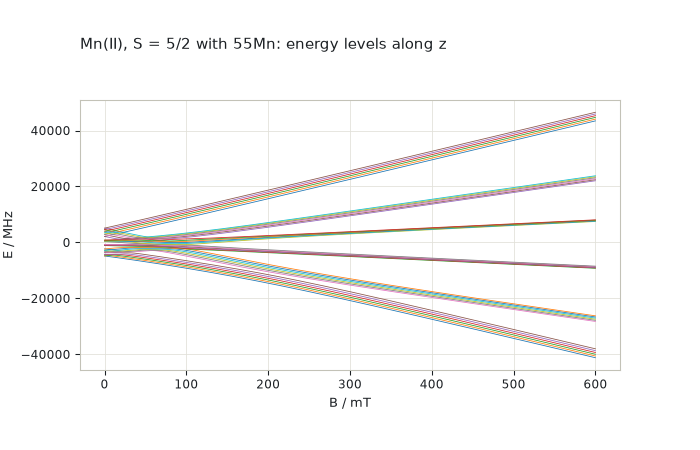

In [8]:
import plotly.graph_objects as go

fields = np.linspace(0, 600, 301)  # mT
E_mn = es.levels(mn, "z", fields)  # (301, 36)
fig = go.Figure()
for k in range(E_mn.shape[1]):
    fig.add_trace(go.Scatter(x=fields, y=E_mn[:, k], mode="lines", line={"width": 1}, showlegend=False))
fig.update_layout(title="Mn(II), S = 5/2 with 55Mn: energy levels along z", xaxis_title="B / mT", yaxis_title="E / MHz", width=700, height=450)
fig

## Rotations, units, nuclear data

`erot` is EasySpin's passive rotation matrix from Euler angles (z, y', z'');
`eulang` inverts it. Spynach's `euler2dcm` is Spinach's active rotation, the
transpose for the same angles. `ang2vec` and `vec2ang` convert between polar
angles and unit vectors.

In [9]:
from spynach.conventions import euler2dcm

angles = [0.4, 1.1, 2.3]
print("erot(angles) is euler2dcm(angles).T:", np.allclose(es.erot(angles), np.asarray(euler2dcm(angles)).T))
print("eulang(erot(angles)):", es.eulang(es.erot(angles)).round(6))
print("ang2vec(phi, theta):", es.ang2vec(0.5, 1.0).ravel().round(4))

erot(angles) is euler2dcm(angles).T: True
eulang(erot(angles)): [0.4 1.1 2.3]
ang2vec(phi, theta): [0.7385 0.4034 0.5403]


`unitconvert` converts between `cm^-1`, `eV`, `K`, `mT` and `MHz`, with a g
factor for the field conversions; `mt2mhz` and `mhz2mt` are the common pair.
The physical constants are module attributes (`es.bmagn`, `es.planck`,
`es.gfree`, ...). `nucdata` reads EasySpin's isotope table (351 isotopes):

In [10]:
print("350 mT at g_e is", es.mt2mhz(350).round(1), "MHz;  1 cm^-1 is", es.unitconvert(1, "cm^-1->MHz").round(1), "MHz")
data = es.nucdata("1H,14N,63Cu")
print("spins", data.spin, " gn", data.gn, " abundance", data.abund)
print("quadrupole moments (barn):", data.qm, " 63Cu natural abundance:", es.nucabund("63Cu"))

350 mT at g_e is 9808.7 MHz;  1 cm^-1 is 29979.2 MHz
spins [0.5 1.  1.5]  gn [5.58569468 0.403761   1.4824    ]  abundance [0.999885 0.99632  0.6917  ]
quadrupole moments (barn): [ 0.       0.02044 -0.22   ]  63Cu natural abundance: [0.6917]


## Resonance fields

A cw EPR spectrum is a field sweep at fixed microwave frequency, so the
central question is at which fields `B` a pair of levels satisfies
`E_v(B) - E_u(B) = h nu`. `resfields(spin_system, exp, opt)` answers it as
EasySpin does: the energy level diagram is modelled over the sweep range by
cubic splines whose segments are bisected until the model is accurate to
`Opt["ModellingAccuracy"]` (a few diagonalisations suffice for a simple
system), the resonance fields are the roots of the cubics, and for each
resonance the transition rate (from the magnetic moment operators in the lab
frame), the frequency-to-field factor `dB/dE` (the general form of the
`1/g` factor), the thermal or non-equilibrium polarisation and, when strains
are given, the line width follow. The experiment is a dict with EasySpin's
fields: `mwFreq` in GHz, `Range` or `CenterSweep` in mT, `Temperature` in K,
`mwMode` (`'perpendicular'`, `'parallel'`, or `[k, alpha]` for a beam direction
and polarisation), `SampleFrame` with one lab-frame orientation per row, and
`MolFrame`. The result is a named tuple: `pos` and `int` are
transitions-by-orientations arrays (`NaN` where a resonance leaves the
range), `wid` the strain widths (FWHM, mT) or `None`, `trans` the level pairs.

In [11]:
nitroxide = {"g": [2.0088, 2.0061, 2.0027], "Nucs": "14N", "A": [16, 16, 86]}
exp = {"mwFreq": 9.5, "Range": [330, 350], "SampleFrame": [[0, 0, 0], [0.3, 1.1, 0.7]]}
res = es.resfields(nitroxide, exp, {"FuzzLevel": 0})
print("transitions:", res.trans.tolist())
print("fields (mT) for the two orientations:\n", res.pos.round(3))
print("intensities (the three allowed lines carry it):\n", res.int.round(4))

transitions: [[1, 5], [1, 6], [2, 4], [2, 5], [2, 6], [3, 4], [3, 5]]
fields (mT) for the two orientations:
 [[337.347 337.479]
 [335.851 336.763]
 [340.415 338.955]
 [338.918 338.248]
 [337.422 337.533]
 [341.987 339.718]
 [340.49  339.011]]
intensities (the three allowed lines carry it):
 [[0.     0.0059]
 [2.3501 2.3277]
 [0.     0.006 ]
 [2.3501 2.3217]
 [0.     0.0059]
 [2.3501 2.3275]
 [0.     0.006 ]]


Two things to know. `Opt["FuzzLevel"]` (EasySpin's default 1e-10) multiplies
the Hamiltonian by random noise to break degeneracies in systems with
several electrons or nuclei; set it to 0 for reproducible numbers. And with
`Opt["Method"] = "hybrid"`, nuclei not listed in `Opt["HybridCoreNuclei"]`
are treated to first order: the core system is diagonalised and each
resonance is split by the nuclear sub-Hamiltonians of the remaining nuclei
(the Mims matrix gives the amplitudes), which is what makes Cu(II) with four
14N tractable.

In [12]:
cu = {"S": 1 / 2, "g": [2.05, 2.2], "Nucs": "63Cu,14N,14N", "A": [[50, 50, 500], [40, 40, 44], [38, 38, 42]]}
exp = {"mwFreq": 9.5, "Range": [260, 360], "SampleFrame": [0.3, 1.1, 0.7]}
matrix = es.resfields(cu, exp, {"FuzzLevel": 0})
hybrid = es.resfields(cu, exp, {"FuzzLevel": 0, "Method": "hybrid", "HybridCoreNuclei": [1]})
print("lines by matrix diagonalisation:", matrix.pos.shape[0], "  hybrid:", hybrid.pos.shape[0])
print("total intensity, matrix and hybrid:", np.nansum(matrix.int).round(4), np.nansum(hybrid.int).round(4))

lines by matrix diagonalisation: 107   hybrid: 90
total intensity, matrix and hybrid: 7.8076 7.8073


Strains broaden each line in proportion to how its field depends on the
strained parameter: `HStrain` (an orientation-dependent residual width in
MHz), `gStrain` and `AStrain` (distributions of the principal values), and
`DStrain` with the `D`-`E` correlation `DStrainCorr`. Temperatures give
Boltzmann polarisations, `initState` non-equilibrium populations, and
`Exp["lightBeam"]` with `Sys["tdm"]` photoselection weights.

In [13]:
strained = {**nitroxide, "HStrain": [10, 10, 30], "gStrain": [0.002, 0.001, 0.001]}
res = es.resfields(strained, {"mwFreq": 9.5, "Range": [330, 350], "Temperature": 4}, {"FuzzLevel": 0})
print("widths (FWHM, mT):", res.wid.ravel().round(4), " intensities at 4 K:", res.int.ravel().round(4))

widths (FWHM, mT): [1.0836 1.0836 1.0836]  intensities at 4 K: [0.1338 0.1338 0.1338]


`resfields_eig` is the exact alternative: the eigenfield method of Belford
et al. turns the resonance condition into a generalised eigenvalue problem in
Liouville space whose eigenvalues are all resonance fields at once, with no
field search. It costs a problem of dimension `n^2`, so it serves as the
reference for small systems:

In [14]:
fields = es.resfields_eig(nitroxide, {"mwFreq": 9.5, "Range": [330, 350], "SampleFrame": [0.3, 1.1, 0.7]})
print("eigenfields (mT):", np.round(fields, 4))

eigenfields (mT): [336.7634 337.4786 337.5333 338.1854 338.2485 338.2959 338.9553 339.0111
 339.718 ]


## Line shapes and spherical grids

The line shapes are EasySpin's, area-normalised, with derivatives (`diff`),
dispersion (`dispersion=True` returns both parts, `phase` mixes them) and the
pseudo-Voigt combination `lshape` and the true Voigt convolution `voigtian`.
`convspec` convolves a spectrum of any dimension with them, one width per
axis; its output keeps the units of the input (a stick of area one gives a
line of area one times the step).

In [15]:
B = np.linspace(330, 350, 2001)
absorption = es.gaussian(B, 340, 0.5)
derivative = es.lorentzian(B, 340, 0.5, 1)
sticks = np.zeros(B.size)
sticks[[400, 1000, 1600]] = [1, 2, 1]
spectrum = es.convspec(sticks, B[1] - B[0], 0.8, 1, 0.5)  # first-derivative pseudo-Voigt lines
print("areas:", (absorption.sum() * (B[1] - B[0])).round(6), " derivative sums to", derivative.sum().round(9))
print("convolved spectrum has", spectrum.size, "points and extrema at", B[[spectrum.argmax(), spectrum.argmin()]].round(2), "mT")

areas: 1.0  derivative sums to -0.0
convolved spectrum has 2001 points and extrema at [339.7 340.3] mT


Powder spectra integrate over orientations on `sphgrid`, EasySpin's SOPHE
grid: knots on a region of the unit sphere chosen by the point group of the
Hamiltonian (`'D2h'` for one octant, `'Ci'` for a hemisphere, `'C1'` for the
whole sphere, `'Dinfh'` for a quarter meridian), with weights summing to
`4 pi`, and the triangulation that the spectrum is projected from:

In [16]:
grid = es.sphgrid("D2h", 19, triangulate=True)
print(grid.n, "knots,", grid.tri_idx.shape[0], "triangles; weights sum to 4 pi:", (grid.weights.sum() / (4 * np.pi)).round(12))
print("first knots (phi, theta):", np.column_stack([grid.phi, grid.theta])[:4].round(4).tolist())

190 knots, 324 triangles; weights sum to 4 pi: 1.0
first knots (phi, theta): [[0.0, 0.0], [0.0, 0.0873], [1.5708, 0.0873], [0.0, 0.1745]]


## Powder and crystal spectra: `pepper`

`pepper(spin_system, exp, opt)` is EasySpin's cw EPR simulator for solids,
and it runs the pipeline above the way EasySpin does. The point group of the
Hamiltonian (`hamsymm`) picks the region of the sphere to integrate over and
`sphgrid` the knots on it; `resfields` (the default `Opt["Method"] =
"matrix"`), the hybrid method, perturbation theory (`"perturb1"`,
`"perturb2"`, for S = 1/2 with the nuclei to first or second order) or the
eigenfield method (`"eig"`, a stick spectrum by brute force) give the
resonance positions, intensities and strain widths on the knots; the
positions are interpolated onto a finer grid (`Opt["GridSize"] = [knots,
refinement]`, cubic splines along the meridians and across the octant) and
projected from the triangles of the grid onto the field axis, which gives
the powder pattern of the resonance positions without binning artefacts; the
pattern is convolved with the isotropic line (`lwpp` or `lw`, Gaussian and
Lorentzian parts), differentiated to `Exp["Harmonic"]` and, with
`Exp["ModAmp"]`, pseudo-modulated. When the width is orientation-dependent
(strains), each resonance is instead added as a line of its own width, from
a template, with the kernel `lisum1i`. The result is a named tuple
`Spectrum(x, spec, info)`; `info["Transitions"]` lists the level pairs. Set
`Opt["FuzzLevel"] = 0` for reproducible numbers.

In [17]:
powder = {**nitroxide, "lwpp": 0.3}
exp = {"mwFreq": 9.5, "Range": [330, 350], "nPoints": 1024}
matrix = es.pepper(powder, exp, {"FuzzLevel": 0})
perturb = es.pepper(powder, exp, {"FuzzLevel": 0, "Method": "perturb2"})
print("transitions:", matrix.info["Transitions"].tolist(), " orientations:", matrix.info["nOrientations"])
print("matrix and second-order perturbation theory differ by", f"{np.abs(matrix.spec - perturb.spec).max() / np.abs(matrix.spec).max():.1%}")

transitions: [[1, 5], [1, 6], [2, 4], [2, 5], [2, 6], [3, 4], [3, 5]]  orientations: 190
matrix and second-order perturbation theory differ by 1.4%


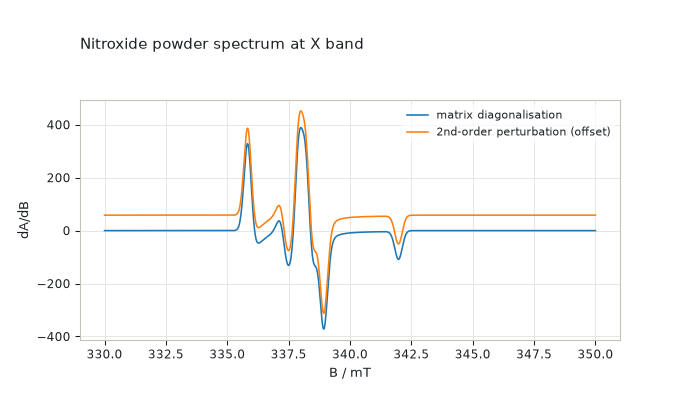

In [18]:
import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(x=matrix.x, y=matrix.spec, mode="lines", name="matrix diagonalisation"))
fig.add_trace(go.Scatter(x=perturb.x, y=perturb.spec + 0.15 * matrix.spec.max(), mode="lines", name="2nd-order perturbation (offset)"))
fig.update_layout(title="Nitroxide powder spectrum at X band", xaxis_title="B / mT", yaxis_title="dA/dB", width=700, height=420)
fig

The methods are chosen as in EasySpin: for Cu(II) with four 14N (648
states) full diagonalisation takes a minute, the hybrid method and
perturbation theory a fraction of a second, and `pepper` selects the grid
and the kernels by itself. Strains make the widths orientation-dependent
and switch `pepper` to the summation path; `Opt["separate"] =
"transitions"` returns one spectrum per transition; `Exp["SampleFrame"]`
rows with `Exp["MolFrame"]` make it a crystal, summed over the orientations
(`Opt["separate"] = "orientations"` keeps them apart), and `Exp["Harmonic"]
= 0` gives the absorption spectrum:

In [19]:
cu4n = {"S": 1 / 2, "g": [2.05, 2.05, 2.2], "Nucs": "63Cu,14N,14N,14N,14N", "A": [[50, 50, 500]] + [[40, 40, 40]] * 4, "lwpp": 1}
cu_exp = {"mwFreq": 9.5, "Range": [260, 360]}
hybrid = es.pepper(cu4n, cu_exp, {"FuzzLevel": 0, "Method": "hybrid", "HybridCoreNuclei": [1]})
second = es.pepper(cu4n, cu_exp, {"FuzzLevel": 0, "Method": "perturb2"})
print("Cu(II) with four 14N: hybrid and perturb2 differ by", f"{np.abs(hybrid.spec - second.spec).max() / np.abs(hybrid.spec).max():.1%}")
strained = es.pepper({**nitroxide, "HStrain": [20, 20, 60]}, exp, {"FuzzLevel": 0})
per_transition = es.pepper(powder, exp, {"FuzzLevel": 0, "separate": "transitions"})
crystal = es.pepper(powder, {**exp, "SampleFrame": [[0, 0, 0], [0.3, 1.1, 0.7]], "MolFrame": [0, 0, 0]}, {"FuzzLevel": 0, "separate": "orientations"})
absorption = es.pepper(powder, {**exp, "Harmonic": 0}, {"FuzzLevel": 0})
print("strained spectrum, per-transition spectra, crystal spectra:", strained.spec.shape, per_transition.spec.shape, crystal.spec.shape)
print("absorption area:", (absorption.spec.sum() * (absorption.x[1] - absorption.x[0])).round(3), " first derivative sums to", matrix.spec.sum().round(9))

Cu(II) with four 14N: hybrid and perturb2 differ by 7.3%
strained spectrum, per-transition spectra, crystal spectra: (1024,) (7, 1024) (2, 1024)
absorption area: 554.171  first derivative sums to -0.0


## Solution spectra: `garlic`

`garlic(spin_system, exp, opt)` simulates isotropic cw spectra of S = 1/2
systems: the line positions come from the Breit-Rabi formula (exact for one
nucleus, iterated for several) or from perturbation theory to the order in
`Opt["Method"]` (`"perturb1"` to `"perturb5"`), equivalent nuclei
(`Sys["n"]`) are coupled with `equivcouple`, and each line gets the
isotropic width (`lwpp` or `lw`, Gaussian and Lorentzian) plus, when
`Sys["tcorr"]` (or `logtcorr`) is given, the fast-motion Lorentzian width of
its mI combination from the anisotropies of g, A and Q (`fastmotion`, the
Kivelson A + B mI + C mI² expression with the spectral densities of the
rotational correlation time). `Exp["Field"]` with `mwRange` gives a
frequency sweep. The lines are accumulated by binning (the default),
summed from a template, or evaluated explicitly (`Opt["AccumMethod"]`).

In [20]:
solution = {"g": [2.0088, 2.0064, 2.0027], "Nucs": "14N", "A": es.unitconvert(np.array([7.59, 5.95, 31.76]) / 10, "mT->MHz"), "lwpp": 0.02}
rigid = es.garlic({**solution, "tcorr": 1e-11}, {"mwFreq": 9.5, "Range": [336, 341], "nPoints": 2048})
slow = es.garlic({**solution, "tcorr": 1e-9}, {"mwFreq": 9.5, "Range": [336, 341], "nPoints": 2048})
widths, mI = es.fastmotion(solution, 340, 1e-9)
print("fast-motion widths (mT) for mI =", mI.ravel().tolist(), ":", widths.round(4))
print("line positions (mT):", np.sort(slow.info["resfields"]).round(3))

fast-motion widths (mT) for mI = [-1.0, 0.0, 1.0] : [0.4216 0.1725 0.168 ]
line positions (mT): [336.857 338.361 339.871]


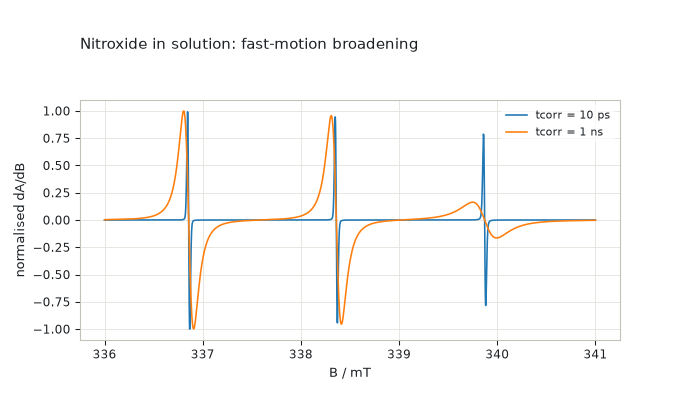

In [21]:
import plotly.graph_objects as go

fig = go.Figure()
fig.add_trace(go.Scatter(x=rigid.x, y=rigid.spec / np.abs(rigid.spec).max(), mode="lines", name="tcorr = 10 ps"))
fig.add_trace(go.Scatter(x=slow.x, y=slow.spec / np.abs(slow.spec).max(), mode="lines", name="tcorr = 1 ns"))
fig.update_layout(title="Nitroxide in solution: fast-motion broadening", xaxis_title="B / mT", yaxis_title="normalised dA/dB", width=700, height=420)
fig

In [22]:
protons = es.garlic({"g": 2.0, "Nucs": "1H,1H", "n": [3, 2], "A": [30, 12], "lw": [0.2, 0]}, {"mwFreq": 9.5, "Range": [325, 352], "Harmonic": 0})
print("CH3-CH2 pattern:", protons.info["resfields"].size, "lines, the strongest at", protons.x[protons.spec.argmax()].round(2), "mT")
sweep = es.garlic({"g": 2.006, "Nucs": "14N", "A": 47, "lw": 0.1}, {"Field": 340, "mwRange": [9.4, 9.6]})
print("frequency sweep at 340 mT: lines at", np.sort(sweep.info["resfields"]).round(4), "GHz")

CH3-CH2 pattern: 24 lines, the strongest at 339.91 mT
frequency sweep at 340 mT: lines at [9.4991 9.5462 9.5931] GHz


## What is checked, and what is pending

`tests/epreasy/test_foundation.py`, `tests/epreasy/test_resfields.py` and
`tests/epreasy/test_pepper.py` check the closed forms (angular momentum algebra, Stevens operators against
their polynomial forms, the free-electron and proton Zeeman energies,
first-order hyperfine splittings, the zero-field levels of a triplet, tensor
frames; the free-electron resonance field and intensity, the spline method
against the eigenfield method, the hybrid method against full
diagonalisation, strain widths, Boltzmann and non-equilibrium polarisations,
photoselection, line-shape areas and derivatives, grid weights; the
kernels against the line shapes and weight conservation, the splines
against SciPy, the point groups of known Hamiltonians, the agreement of
`pepper`'s methods with each other and with `garlic` on an isotropic
system, `garlic`'s line spacings and equivalent-nuclei amplitudes, the
fast-motion widths in the fast limit, field modulation against the
derivative) and `tests/epreasy/test_parity.py`,
`tests/epreasy/test_parity_resfields.py` and
`tests/epreasy/test_parity_pepper.py` compare every stage with EasySpin
6.0.15 on the cases written by `oracle/matlab/easyspin/dumps/esdump_ham.m`,
`esdump_resfields.m` and `esdump_pepper.m`: a nitroxide with tilted frames, a Cu(II) with two 14N, an S = 5/2 Mn(II) with
D, E and a rank-4 Stevens term, a radical pair with J, dipolar, antisymmetric
and biquadratic exchange, a triplet with full g, D, A and Q matrices and two
coupled nuclei; resonance fields of these in the matrix and hybrid methods,
with strains, temperatures, excitation modes and photoselection; the
eigenfield method; the line shapes; the grids; 32 `pepper` spectra (the
nitroxide by every method, with and without interpolation, separate
transitions, modulation, dispersion, second harmonic, temperature, parallel
mode, H/g/A strains, axial and rhombic g, tilted frames, Mn(II), a triplet
with D strain, Cu(II) with four 14N, crystals) and 14 `garlic` spectra
(exact and perturbation positions, the accumulation methods, Gaussian and
Lorentzian widths, modulation, temperature, dispersion, equivalent protons,
Cu with 14N, fast motion, frequency sweeps), plus `fastmotion`, `hamsymm`,
`fieldmod` and `equivcouple`. The measured agreement is in
[`porting/EASYSPIN_FIXTURES.md`](../../porting/EASYSPIN_FIXTURES.md). In
`pepper`, frequency sweeps, isotope mixtures (`Nucs = "Cu"`), partial
ordering (`Exp["Ordering"]`), sample rotations and `Opt["ImmediateBinning"]`
are not ported yet; `salt`, `curry`, `chili`, `saffron`, `spidyan` and
`esfit` are the next phases; orbital angular momentum, higher-order Zeeman
terms, tilted Stevens-operator frames and crystal symmetries beyond P1 are
not ported.